# WattRota — Senaryo karşılaştırmaları

## 1. Araştırma soruları ve deney düzeni

1. Aynı üretim koşullarında farklı elektrik fiyatlarıyla maliyet avantajı bulunabiliyor mu?
2. Yükleme kapasitesine yaklaşan talepte teslim ve stok koşulları korunabiliyor mu?
3. Üretim planını değiştirmenin gideri yükseldiğinde üretim saatlerini korumak daha iyi sonuç veriyor mu?

Fiyat denemeleri için 6–8 Ocak, 7–9 Nisan ve 7–9 Temmuz 2025 dönemleri seçildi. Hepsi pazartesi–çarşamba günlerini kapsar. Aynı talep, başlangıç stokları, teslim pencereleri ve göreli bakım takvimi bu tarihlere taşındı. Bu tarihler sonuçlara göre seçilmedi. Temel örnek 6–8 Ekim 2025'tir.

Yoğun talepte yalnızca ikinci günün UR02 dökme siparişi 400 tondan 560 tona yükseltildi. Toplam talep %2,38 artar; o gün dökme yükleme kaynağı için gereken en az süre 9 saatlik takvimin tamamına ulaşır. Bu senaryonun referansı, aynı yeni talebi karşılayacak şekilde fiyatlardan bağımsız düzenlendi.

Yüksek değişiklik gideri 10.000 TL/üretim kaynak-saati olarak tanımlanan bir davranış testidir; gerçek maliyet tahmini değildir. Yükleme saatleri bu cezanın dışındadır. Negatif kontrolde ise ikinci günün UR02 torbalı siparişi 800 tona çıkarıldı; gereken yükleme süresi takvimi aşar.

Fiyatların tamamı biliniyor kabul edilir. Uygulanabilir senaryolarda ana arama sınırı 120 saniye, hedef göreli açık %0,1'dir; ön aramada dört alt problem en fazla 10'ar saniye çalışır. Zaman sınırında bulunan sonuçlar kesin optimum olarak sunulmaz. Her öneri kendi senaryosunun referansıyla karşılaştırılır.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

proje = Path.cwd()
if not (proje / "src").is_dir():
    proje = proje.parent
sys.path.insert(0, str(proje / "src"))
from firma_cizelgeleme import firma_verisini_oku, maliyet_ve_ozet
from firma_senaryolari import senaryolari_hazirla, yukleme_kapasitesini_kontrol_et

senaryolar = senaryolari_hazirla(proje)
sonuc_dizini = proje / "data/results/firma_01_senaryolar"
temel = firma_verisini_oku(proje)

## 2. Girdilerin ve önerilerin bağımsız kontrolü

Her senaryonun kullanılan tabloları `girdiler.zip` içinde CSV olarak saklanır. Arşivler, güncel kaynaklardan yeniden hazırlanan senaryolarla eşleştirilir. Önerilen planlar saat saat yeniden denetlenir ve maliyetleri çözücüden ayrı hesaplanır. Kapasiteyi aşan senaryoda ekonomik sonuç üretilmez.

In [2]:
sonuclar = {}
satirlar = []
for sid, case in senaryolar.items():
    klasor = sonuc_dizini / sid
    bilgi = json.loads((klasor / "sonuc.json").read_text(encoding="utf-8"))
    for ad, beklenen in bilgi["kaynak_sha256"].items():
        assert hashlib.sha256((proje / ad).read_bytes()).hexdigest() == beklenen, ad
    assert hashlib.sha256((klasor / "girdiler.zip").read_bytes()).hexdigest() == bilgi["girdi_zip_sha256"]
    v = case["veriler"]
    with ZipFile(klasor / "girdiler.zip") as arsiv:
        for ad, beklenen in v.items():
            with arsiv.open(ad + ".csv") as dosya:
                kayit = pd.read_csv(dosya, keep_default_na=False, encoding="utf-8-sig")
            for alan in beklenen.columns:
                if pd.api.types.is_datetime64_any_dtype(beklenen[alan]):
                    kayit[alan] = pd.to_datetime(kayit[alan])
            pd.testing.assert_frame_equal(kayit, beklenen.reset_index(drop=True), check_dtype=False)
    kapasite = yukleme_kapasitesini_kontrol_et(v)
    if bilgi["uygulanabilir"]:
        plan = pd.read_csv(klasor / "onerilen_plan.csv", keep_default_na=False)
        yuk = pd.read_csv(klasor / "onerilen_yuklemeler.csv")
        plan["tarih_saat"] = pd.to_datetime(plan["tarih_saat"])
        yuk["tarih_saat"] = pd.to_datetime(yuk["tarih_saat"])
        ozet = maliyet_ve_ozet(v, plan, yuk, case["degisiklik_gideri"])[-1]
        ref = maliyet_ve_ozet(v, v["referans_plan"], v["referans_yuklemeler"], case["degisiklik_gideri"])[-1]
        assert np.isclose(ozet.iloc[-1], bilgi["onerilen_maliyet_tl"], atol=0.02, rtol=0)
        assert np.isclose(ref.iloc[-1], bilgi["referans_maliyet_tl"], atol=0.02, rtol=0)
        assert ozet.iloc[-1] <= ref.iloc[-1] + 0.02
        satirlar.append([case["ad"], bilgi["toplam_siparis_ton"], ref.iloc[-1], ozet.iloc[-1],
                        bilgi["avantaj_tl"], bilgi["avantaj_yuzde"],
                        bilgi["degisen_uretim_kaynak_saat"], 100*bilgi["cozum"]["goreli_acik"],
                        "Kontroller geçti", bilgi["cozum"]["durum"]])
        bilgi["yuklemeler"] = yuk
    else:
        assert kapasite["kapasite_celiskisi"].any()
        assert not bilgi["cozum_calistirildi"]
        satirlar.append([case["ad"], bilgi["toplam_siparis_ton"], np.nan, np.nan,
                        np.nan, np.nan, np.nan, np.nan,
                        "Yükleme kapasitesi yetersiz", "Çözücü çalıştırılmadı"])
    sonuclar[sid] = bilgi

temel_dizin = proje / "data/results/firma_01_cizelgeleme"
temel_bilgi = json.loads((temel_dizin / "cozum_bilgisi.json").read_text(encoding="utf-8"))
for ad, beklenen in temel_bilgi["dosya_sha256"].items():
    assert hashlib.sha256((proje / ad).read_bytes()).hexdigest() == beklenen, ad
temel_tablo = pd.read_csv(temel_dizin / "karsilastirma.csv", index_col="olcut")
ref = temel_tablo.loc["Karşılaştırılan toplam maliyet (TL)", "Referans"]
onerilen = temel_tablo.loc["Karşılaştırılan toplam maliyet (TL)", "Önerilen"]
satirlar.insert(0, ["Temel — Ekim fiyatları", 6720, ref, onerilen, ref-onerilen,
                   100*(ref-onerilen)/ref, temel_tablo.loc["Değişen kaynak-saat", "Önerilen"],
                   100*temel_bilgi["goreli_acik"], "Kontroller geçti", temel_bilgi["durum"]])
karsilastirma = pd.DataFrame(satirlar, columns=[
    "Senaryo", "Sipariş (ton)", "Referans maliyet (TL)", "Önerilen maliyet (TL)",
    "Avantaj (TL)", "Avantaj (%)", "Değişen üretim kaynak-saat", "Optimalite açığı (%)",
    "Kontrol", "Çözücü durumu"])
print("Beş yeni uygulanabilir senaryonun girdileri, planları ve maliyetleri yeniden doğrulandı.")
kayitli_ozet = pd.read_csv(sonuc_dizini / "senaryo_karsilastirmasi.csv")
pd.testing.assert_frame_equal(karsilastirma, kayitli_ozet, check_dtype=False)
karsilastirma.round(2)

Beş yeni uygulanabilir senaryonun girdileri, planları ve maliyetleri yeniden doğrulandı.


,Senaryo,Sipariş (ton),Referans maliyet (TL),Önerilen maliyet (TL),Avantaj (TL),Avantaj (%),Değişen üretim kaynak-saat,Optimalite açığı (%),Kontrol,Çözücü durumu
0,Temel — Ekim fiyatları,6720.0,652799.66,644855.65,7944.01,1.22,54.0,3.04,Kontroller geçti,Time limit reached
1,Kış fiyatları,6720.0,584954.19,580118.62,4835.57,0.83,36.0,3.02,Kontroller geçti,Time limit reached
2,İlkbahar fiyatları,6720.0,636666.76,635617.91,1048.85,0.16,62.0,2.62,Kontroller geçti,Time limit reached
3,Yaz fiyatları,6720.0,718677.54,718546.16,131.37,0.02,0.0,2.14,Kontroller geçti,Time limit reached
4,Yoğun dökme talep,6880.0,667955.79,660429.48,7526.31,1.13,76.0,2.75,Kontroller geçti,Time limit reached
5,Yüksek üretim planı değişikliği gideri,6720.0,652799.66,652492.07,307.59,0.05,0.0,0.07,Kontroller geçti,Optimal
6,Yükleme kapasitesini aşan talep,7120.0,NaN,NaN,NaN,NaN,NaN,NaN,Yükleme kapasitesi yetersiz,Çözücü çalıştırılmadı


## 3. Fiyatlar değiştiğinde sonuç

Bu bölümde talep ve üretim koşulları aynıdır. Yalnızca farklı dönemlerin gerçekleşmiş elektrik fiyatları kullanılır. Fiyat seviyeleri ve saatlik şekil birlikte değişir; karşılaştırma tek başına herhangi bir piyasa nedenini açıklamaz.

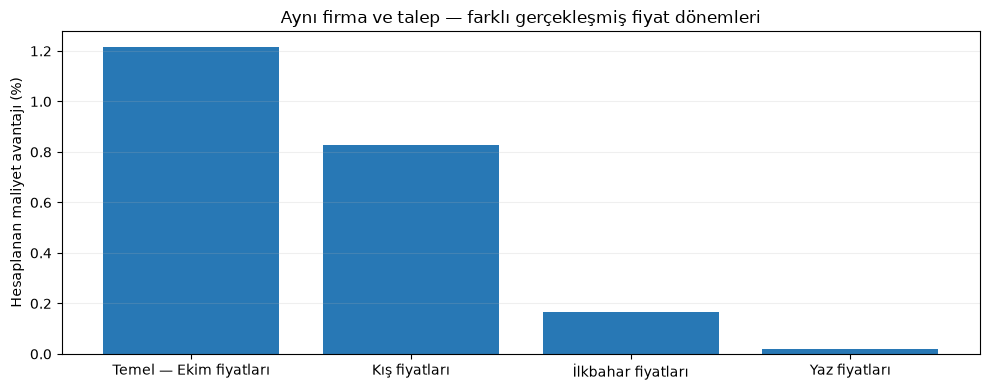

,Senaryo,Avantaj (TL),Avantaj (%),Optimalite açığı (%)
0,Temel — Ekim fiyatları,7944.01,1.22,3.04
1,Kış fiyatları,4835.57,0.83,3.02
2,İlkbahar fiyatları,1048.85,0.16,2.62
3,Yaz fiyatları,131.37,0.02,2.14


In [3]:
fiyat_senaryolari = karsilastirma.iloc[:4]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(fiyat_senaryolari["Senaryo"], fiyat_senaryolari["Avantaj (%)"], color="#2878b5")
ax.set_ylabel("Hesaplanan maliyet avantajı (%)")
ax.set_title("Aynı firma ve talep — farklı gerçekleşmiş fiyat dönemleri")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

fiyat_senaryolari[["Senaryo", "Avantaj (TL)", "Avantaj (%)", "Optimalite açığı (%)"]].round(2)

## 4. Yoğun talep ve kapasite sınırı

İkinci günün yükleme koşulları karşılaştırılır. Zorunlu süre, her sipariş miktarının saatlik yükleme kapasitesine bölünüp yukarı yuvarlanmasıyla hesaplanır. Aynı saatte bir kaynakta tek sipariş işlenebilir. Bu alt sınırın takvimi aşması uygulanamazlığı kanıtlar; aşmaması ise stok ve teslim koşullarının da sağlandığını tek başına kanıtlamaz.

In [4]:
kapasite_tablolari = []
for ad, v in [("Temel", temel),
              ("Yoğun dökme talep", senaryolar["yogun_dokme_talep"]["veriler"]),
              ("Kapasite aşımı", senaryolar["kapasite_asimi"]["veriler"])]:
    kontrol = yukleme_kapasitesini_kontrol_et(v)
    kontrol = kontrol[kontrol["gun"] == pd.Timestamp("2025-10-07")].copy()
    kontrol.insert(0, "senaryo", ad)
    kapasite_tablolari.append(kontrol)
pd.concat(kapasite_tablolari, ignore_index=True)

,senaryo,gun,kaynak_id,zorunlu_saat_alt_siniri,uygun_saat,kapasite_celiskisi
0,Temel,2025-10-07,Y01,8,9,False
1,Temel,2025-10-07,Y02,9,10,False
2,Yoğun dökme talep,2025-10-07,Y01,9,9,False
3,Yoğun dökme talep,2025-10-07,Y02,9,10,False
4,Kapasite aşımı,2025-10-07,Y01,8,9,False
5,Kapasite aşımı,2025-10-07,Y02,12,10,True


In [5]:
karsilastirma[karsilastirma["Senaryo"].isin([
    "Yoğun dökme talep", "Yükleme kapasitesini aşan talep"
])].round(2)

,Senaryo,Sipariş (ton),Referans maliyet (TL),Önerilen maliyet (TL),Avantaj (TL),Avantaj (%),Değişen üretim kaynak-saat,Optimalite açığı (%),Kontrol,Çözücü durumu
4,Yoğun dökme talep,6880.0,667955.79,660429.48,7526.31,1.13,76.0,2.75,Kontroller geçti,Time limit reached
6,Yükleme kapasitesini aşan talep,7120.0,NaN,NaN,NaN,NaN,NaN,NaN,Yükleme kapasitesi yetersiz,Çözücü çalıştırılmadı


## 5. Üretim planını değiştirmek pahalı olduğunda

Ceza yalnızca üretim/paketleme kaynağının referansa göre durum veya ürün değiştirdiği saatleri kapsar. Bu nedenle üretim saatleri korunurken yükleme saatleri değişebilir. Aşağıdaki iki gösterge ayrı izlenir.

In [6]:
yuksek = sonuclar["yuksek_degisim_gideri"]
eski_yuk = temel["referans_yuklemeler"]
yeni_yuk = yuksek["yuklemeler"]
anahtar = ["siparis_id", "kaynak_id", "tarih_saat"]
fark = eski_yuk.merge(yeni_yuk, on=anahtar, how="outer", suffixes=("_ref", "_onerilen"))
degisen_yuk_kaydi = (~np.isclose(fark["miktar_ton_ref"].fillna(0),
                               fark["miktar_ton_onerilen"].fillna(0), atol=1e-6)).sum()
print("Değişen üretim/paketleme kaynak-saati:", yuksek["degisen_uretim_kaynak_saat"])
print("Miktarı veya saati değişen yükleme kayıtları:", degisen_yuk_kaydi)
print(f"Karşılaştırılan toplam avantaj: {yuksek['avantaj_tl']:,.2f} TL")
print("Yükleme kayıtları sipariş–kaynak–saat anahtarıyla karşılaştırıldı; taşınan bir yük iki kayıtta fark oluşturabilir.")

Değişen üretim/paketleme kaynak-saati: 0
Miktarı veya saati değişen yükleme kayıtları: 44
Karşılaştırılan toplam avantaj: 307.59 TL
Yükleme kayıtları sipariş–kaynak–saat anahtarıyla karşılaştırıldı; taşınan bir yük iki kayıtta fark oluşturabilir.


## 6. Bulgular ve sonuçların kapsamı

- Dört fiyat örneğinde bulunan maliyet avantajı %0,02–%1,22 arasında değişti. Bu çalıştırmada avantaj tek bir fiyat dönemine özgü kalmadı; büyüklüğü ise belirgin biçimde değişti.
- Yoğun dökme talepte teslim, stok ve güç koşulları korunarak kendi referansına göre %1,13 daha düşük maliyetli plan bulundu.
- Yaz örneğinde üretim kaynaklarının durumu/ürünü değişmedi. Bulunan 131,37 TL avantaj yalnızca yükleme düzeninden geldi. Kalan optimalite açığı nedeniyle üretimde daha iyi değişiklik bulunamayacağı sonucu çıkarılmaz.
- Yüksek değişiklik giderinde üretim/paketleme saatleri korundu; ceza kapsamı dışındaki yükleme düzenlemesiyle 307,59 TL avantaj bulundu.
- Kapasiteyi aşan talep için en az 12 saatlik yüklemeye karşı yalnızca 10 saat bulunması nedeniyle geçerli bir plan sunulmadı.


Sonuçlar bu firmanın tanımlı senaryoları ve bilinen geçmiş fiyatları için geçerlidir. Her uygun plan aynı senaryonun referansına göre değerlendirilir; farklı talep düzeylerinin mutlak maliyet farkları tasarruf diye karşılaştırılmaz. Süre sınırındaki sonuçlarda bulunan avantaj uygulanabilir bir planın avantajıdır; erişilebilecek en yüksek kazanç olduğu kanıtlanmış değildir.

Kapasiteyi aşan negatif kontrolde bir çizelge veya maliyet avantajı sunulmaz. Fiyat tahmin doğruluğu, gerçek tesis uygulaması ve vergi/sözleşme dahil nihai elektrik faturası bu deneyin ölçtüğü sonuçlar değildir.

Deney tanımları `src/firma_senaryolari.py`, senaryo sonuçları `data/results/firma_01_senaryolar` klasöründedir.